# Laboratorio 07: House Prices con regresión lineal

**Objetivo:** realizar un análisis exploratorio (EDA), explicar la regresión lineal y generar predicciones para Kaggle.

Se usa exclusivamente `LinearRegression`, que estima sus coeficientes mediante mínimos cuadrados. Primero reproducimos el enfoque **simple** del material del profesor; luego lo extendemos a regresión **múltiple**. Esta extensión debe confirmarse si la consigna exige una sola variable. No usamos Ridge, árboles ni ensambles.

La competencia evalúa RMSE entre logaritmos de precios: **menor es mejor**. Un resultado 0 sería perfecto; no es una meta realista ni un requisito del laboratorio. El puntaje local no es el puntaje del leaderboard.

Referencia del curso: *PPT-BI-S07-RLAZO-202602*, diapositivas 5–7 y 15–18. Fuentes: [competencia](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques), [LinearRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html).

## 1. Librerías y configuración
Ejecuta las celdas en orden con el intérprete `lab02_alca`. DataSpell administra el servidor Jupyter. La primera salida permite verificar qué Python utiliza el kernel.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Python:", sys.version.split()[0])
print("Intérprete:", sys.executable)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)
SEMILLA = 42

Python: 3.11.16
Intérprete: C:\Users\dark_\miniconda3\envs\lab02_alca\python.exe


## 2. Cargar y comprobar los datos
`train.csv` tiene precios conocidos; `test.csv` no contiene `SalePrice` y solo se utiliza al final. `Id` identifica la vivienda y no es un predictor. Conservamos la carpeta que descargaste.

In [2]:
RAIZ = Path.cwd()
DATOS = RAIZ / "house-prices-advanced-regression-techniques"
SALIDA = RAIZ / "outputs"
SALIDA.mkdir(exist_ok=True)
archivos = ["train.csv", "test.csv", "sample_submission.csv", "data_description.txt"]
for archivo in archivos:
    if not (DATOS / archivo).exists():
        raise FileNotFoundError(f"Falta {archivo}. Abre el notebook desde la raíz de lab07_alca.")

train = pd.read_csv(DATOS / "train.csv")
test = pd.read_csv(DATOS / "test.csv")
ejemplo = pd.read_csv(DATOS / "sample_submission.csv")
assert train["Id"].is_unique and test["Id"].is_unique
assert "SalePrice" not in test.columns
assert train["SalePrice"].gt(0).all()
print("Entrenamiento:", train.shape, "| Competencia:", test.shape)
print("Filas duplicadas:", train.duplicated().sum())
display(train.head())

Entrenamiento: (1460, 81) | Competencia: (1459, 80)
Filas duplicadas: 0


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 3. Reservar validación antes del EDA
Reservamos el 20% de las viviendas conocidas. Exploraremos el 80% restante para que decisiones basadas en precios no dependan de la validación. La imputación y codificación se aprenderán dentro de cada entrenamiento. La semilla permite reproducir la división.

In [3]:
desarrollo, validacion = train_test_split(train, test_size=0.20, random_state=SEMILLA)
desarrollo = desarrollo.copy()
validacion = validacion.copy()
print("Desarrollo:", len(desarrollo), "| Validación:", len(validacion))
display(desarrollo.describe())
display(desarrollo.dtypes.value_counts().rename("Cantidad"))

Desarrollo: 1168 | Validación: 292


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1168.000000,1168.000000,951.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1162.000000,1168.000000,...,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000
mean,730.904966,56.849315,70.343849,10689.642123,6.121575,5.584760,1970.965753,1984.897260,103.771945,446.023973,...,95.946918,49.578767,21.839041,3.812500,15.407534,2.955479,51.267123,6.356164,2007.818493,181441.541952
std,425.369088,42.531862,24.897021,10759.366198,1.367619,1.116062,30.675495,20.733955,173.032238,459.070977,...,129.685939,69.433580,62.083227,31.519664,55.881148,41.648504,553.039684,2.670707,1.322639,77263.583862
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,360.750000,20.000000,59.000000,7587.250000,5.000000,5.000000,1953.000000,1966.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,130000.000000
50%,732.500000,50.000000,70.000000,9600.000000,6.000000,5.000000,1972.000000,1994.000000,0.000000,384.500000,...,0.000000,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,165000.000000
75%,1101.750000,70.000000,80.000000,11700.000000,7.000000,6.000000,2001.000000,2004.000000,166.000000,721.000000,...,168.000000,74.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214925.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1378.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,745000.000000


str        43
int64      35
float64     3
Name: Cantidad, dtype: int64

## 4. EDA: datos faltantes y distribución del precio
Un valor faltante puede indicar ausencia de una instalación, según `data_description.txt`. Para este primer modelo numérico utilizamos medianas y, en las categorías elegidas, una etiqueta `SinDato`. Es una simplificación documentada; no confundimos ausencia con un cero universal.

,Cantidad,%
PoolQC,1162,99.486301
MiscFeature,1122,96.061644
Alley,1094,93.664384
Fence,935,80.051370
MasVnrType,683,58.476027
FireplaceQu,547,46.832192
LotFrontage,217,18.578767
GarageQual,64,5.479452
GarageFinish,64,5.479452
GarageType,64,5.479452


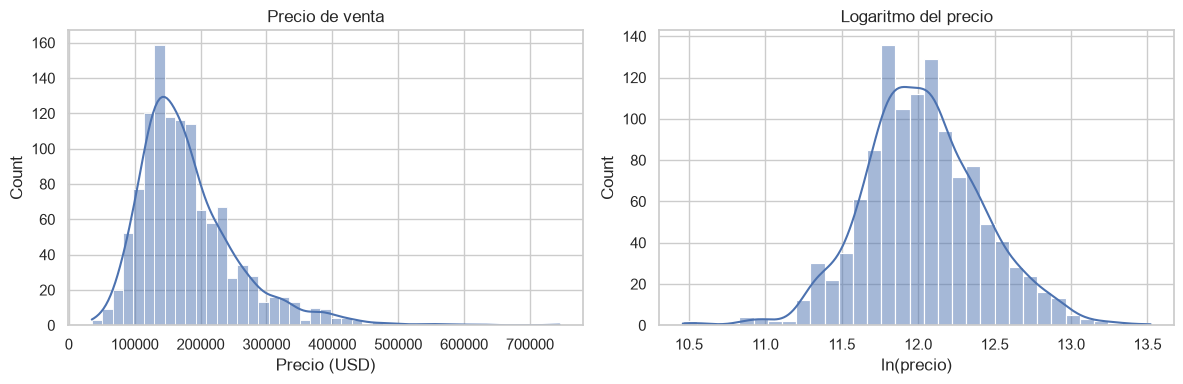

Asimetría original: 1.743
Asimetría logarítmica: 0.125


In [4]:
faltantes = desarrollo.isna().sum().sort_values(ascending=False)
tabla_faltantes = pd.DataFrame({"Cantidad": faltantes, "%": 100 * faltantes / len(desarrollo)})
display(tabla_faltantes[tabla_faltantes["Cantidad"] > 0].head(20))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(desarrollo["SalePrice"], kde=True, ax=axes[0])
axes[0].set(title="Precio de venta", xlabel="Precio (USD)")
sns.histplot(np.log(desarrollo["SalePrice"]), kde=True, ax=axes[1])
axes[1].set(title="Logaritmo del precio", xlabel="ln(precio)")
plt.tight_layout()
plt.show()
print("Asimetría original:", round(desarrollo["SalePrice"].skew(), 3))
print("Asimetría logarítmica:", round(np.log(desarrollo["SalePrice"]).skew(), 3))

**Interpretación:** la distribución original tiene una cola hacia viviendas caras. El logaritmo comprime esa cola y coincide con la escala evaluada por Kaggle. Aplicar logaritmos al precio no convierte la tarea en regresión logística: sigue siendo regresión lineal, ahora sobre `ln(SalePrice)`.

## 5. EDA: relaciones y posibles atípicos
`GrLivArea` es superficie habitable sobre el suelo, en pies cuadrados; `OverallQual` es calidad general de 1 a 10; `Neighborhood` es el barrio. La correlación muestra asociación, no causalidad. Los atípicos se muestran y conservan: no eliminamos viviendas solo para mejorar el score.

OverallQual     0.785555
GrLivArea       0.695652
GarageCars      0.640991
GarageArea      0.624139
TotalBsmtSF     0.597766
1stFlrSF        0.587883
FullBath        0.552546
TotRmsAbvGrd    0.520388
YearBuilt       0.516501
YearRemodAdd    0.508593
GarageYrBlt     0.480351
MasVnrArea      0.459123
Name: Correlación con SalePrice, dtype: float64

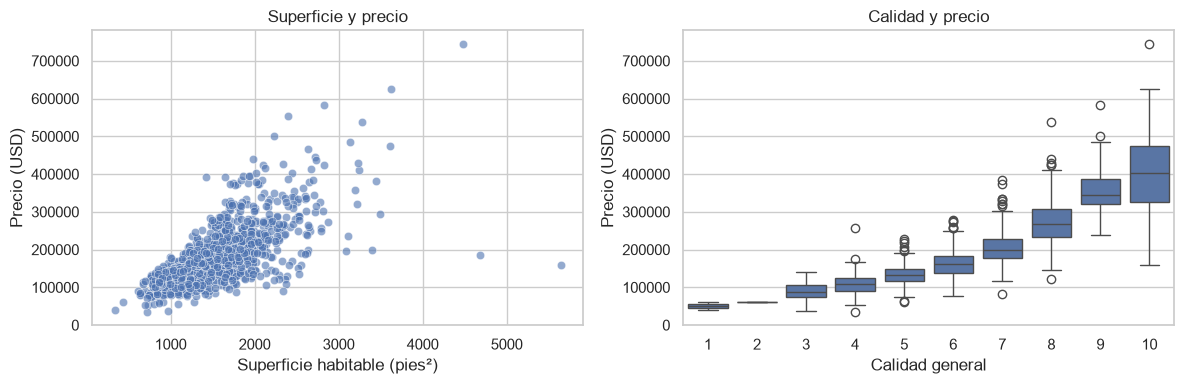

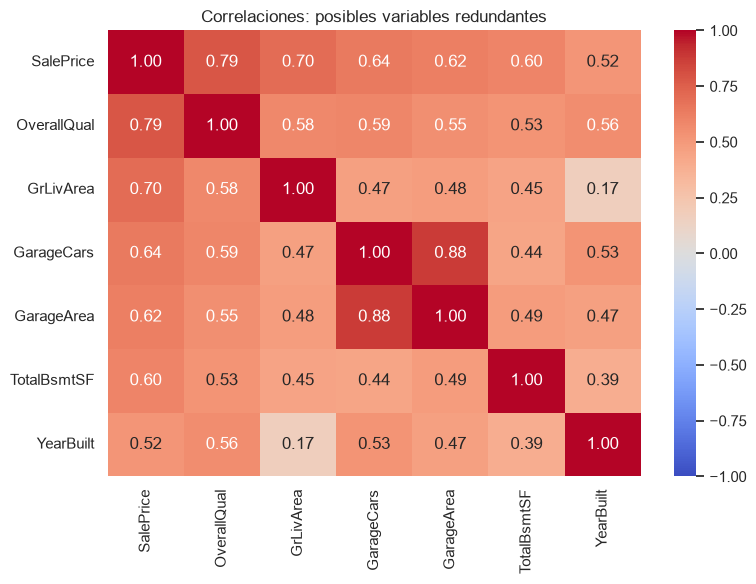

,count,median
Neighborhood,,
MeadowV,10,89500.0
BrDale,13,100000.0
IDOTRR,26,108950.0
BrkSide,45,120000.0
Edwards,87,123500.0
Blueste,1,124000.0
OldTown,91,124000.0
Sawyer,58,134950.0
SWISU,21,139500.0


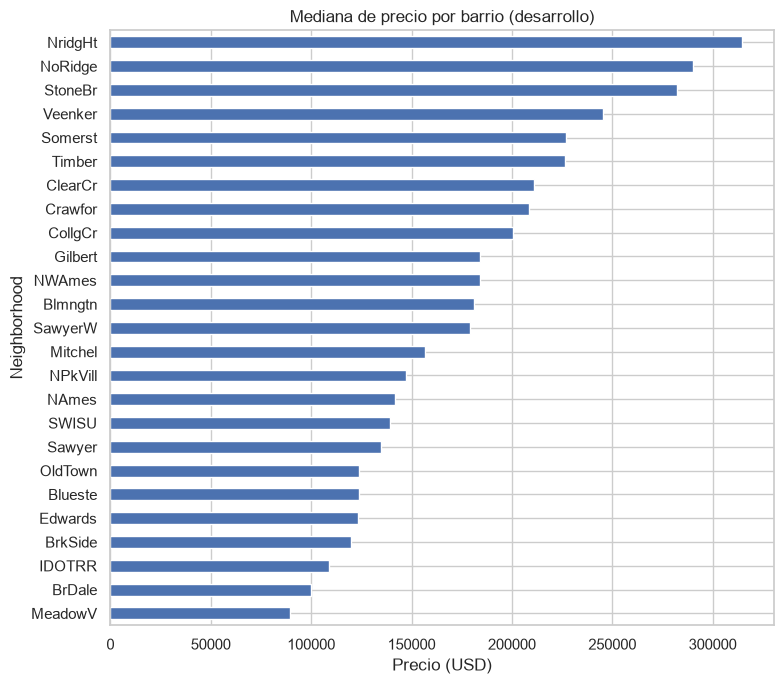

,Id,GrLivArea,SalePrice
1298,1299,5642,160000
523,524,4676,184750
1182,1183,4476,745000
1169,1170,3627,625000
185,186,3608,475000


In [5]:
correlaciones = desarrollo.select_dtypes(include="number").drop(columns="Id").corr()["SalePrice"].drop("SalePrice").sort_values(ascending=False)
display(correlaciones.head(12).rename("Correlación con SalePrice"))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=desarrollo, x="GrLivArea", y="SalePrice", ax=axes[0], alpha=0.6)
axes[0].set(title="Superficie y precio", xlabel="Superficie habitable (pies²)", ylabel="Precio (USD)")
sns.boxplot(data=desarrollo, x="OverallQual", y="SalePrice", ax=axes[1])
axes[1].set(title="Calidad y precio", xlabel="Calidad general", ylabel="Precio (USD)")
plt.tight_layout()
plt.show()

columnas_corr = ["SalePrice", "OverallQual", "GrLivArea", "GarageCars", "GarageArea", "TotalBsmtSF", "YearBuilt"]
plt.figure(figsize=(8, 6))
sns.heatmap(desarrollo[columnas_corr].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlaciones: posibles variables redundantes")
plt.tight_layout()
plt.show()

barrios = desarrollo.groupby("Neighborhood")["SalePrice"].agg(["count", "median"]).sort_values("median")
display(barrios)
barrios["median"].plot.barh(figsize=(8, 7), title="Mediana de precio por barrio (desarrollo)")
plt.xlabel("Precio (USD)")
plt.tight_layout()
plt.show()
display(desarrollo.nlargest(5, "GrLivArea")[["Id", "GrLivArea", "SalePrice"]])

## 6. Regresión lineal simple: el enfoque de clase
Modelo: `precio estimado = intercepto + pendiente × GrLivArea`.

La pendiente representa el cambio asociado en USD por un pie cuadrado adicional. El intercepto corresponde a superficie cero, fuera del rango práctico: no se interpreta como precio real de una vivienda. Verificamos también mínimos cuadrados manualmente. Todas estas estimaciones usan solo desarrollo.

Precio estimado = 24,899.75 + 102.49 × GrLivArea
Un pie² adicional se asocia a 102.49 USD más, en promedio.
R² en desarrollo: 0.4839


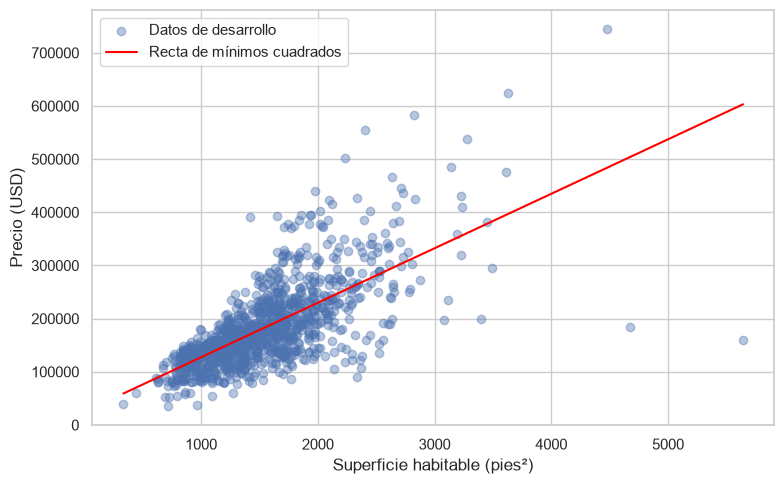

In [6]:
x = desarrollo["GrLivArea"]
y = desarrollo["SalePrice"]
pendiente = ((x - x.mean()) * (y - y.mean())).sum() / ((x - x.mean()) ** 2).sum()
intercepto = y.mean() - pendiente * x.mean()
simple = LinearRegression()
simple.fit(desarrollo[["GrLivArea"]], y)
assert np.isclose(pendiente, simple.coef_[0])
assert np.isclose(intercepto, simple.intercept_)
print(f"Precio estimado = {intercepto:,.2f} + {pendiente:,.2f} × GrLivArea")
print(f"Un pie² adicional se asocia a {pendiente:,.2f} USD más, en promedio.")
print("R² en desarrollo:", round(simple.score(desarrollo[["GrLivArea"]], y), 4))
linea = pd.DataFrame({"GrLivArea": np.linspace(x.min(), x.max(), 100)})
plt.figure(figsize=(8, 5))
plt.scatter(x, y, alpha=0.4, label="Datos de desarrollo")
plt.plot(linea["GrLivArea"], simple.predict(linea), color="red", label="Recta de mínimos cuadrados")
plt.xlabel("Superficie habitable (pies²)")
plt.ylabel("Precio (USD)")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Extensión: variables para regresión múltiple
Múltiple significa varios predictores con el mismo método de mínimos cuadrados. Seleccionamos un grupo pequeño con sentido de negocio, en lugar de incorporar todas las columnas.

Usamos calidad, superficie, capacidad del garaje, antigüedad, baños y chimeneas, además de barrio y calidades de instalaciones. `GarageArea` se omite porque aporta información semejante a `GarageCars`. Transformamos las superficies con `log1p` (acepta cero), y calculamos antigüedades con el año de venta. No se usa el precio para crear estas variables.

La categoría de referencia se omite con `drop="first"` para evitar columnas redundantes con el intercepto. Una categoría nueva en validación/test se codifica como referencia: es una limitación del modelo.

In [7]:
def preparar_variables(datos):
    resultado = datos.copy()
    resultado["LogGrLivArea"] = np.log1p(resultado["GrLivArea"])
    resultado["LogTotalBsmtSF"] = np.log1p(resultado["TotalBsmtSF"])
    resultado["LogLotArea"] = np.log1p(resultado["LotArea"])
    resultado["Antiguedad"] = resultado["YrSold"] - resultado["YearBuilt"]
    resultado["DesdeRemodelacion"] = resultado["YrSold"] - resultado["YearRemodAdd"]
    return resultado

numericas = ["OverallQual", "OverallCond", "LogGrLivArea", "LogTotalBsmtSF", "LogLotArea",
             "GarageCars", "Antiguedad", "DesdeRemodelacion", "FullBath", "HalfBath", "Fireplaces"]
categoricas = ["Neighborhood", "MSZoning", "ExterQual", "KitchenQual", "BsmtQual", "SaleCondition"]
X_des = preparar_variables(desarrollo)
X_val = preparar_variables(validacion)
y_des_log = np.log(desarrollo["SalePrice"])

preparacion_simple = ColumnTransformer([
    ("numero", SimpleImputer(strategy="median"), ["GrLivArea"])
])
preparacion_multiple = ColumnTransformer([
    ("numero", SimpleImputer(strategy="median"), numericas),
    ("categoria", Pipeline([
        ("faltantes", SimpleImputer(strategy="constant", fill_value="SinDato")),
        ("indicadores", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))
    ]), categoricas)
])
modelos = {
    "Simple log": Pipeline([("preparacion", preparacion_simple), ("regresion", LinearRegression())]),
    "Multiple log": Pipeline([("preparacion", preparacion_multiple), ("regresion", LinearRegression())])
}

## 8. Comparar dentro de desarrollo: validación cruzada
Dividimos desarrollo en cinco partes. Cada modelo entrena con cuatro y predice la restante; repetimos cinco veces. El `Pipeline` vuelve a aprender medianas y categorías en cada entrenamiento, evitando fuga de información.

Comparamos dos regresiones lineales sobre logaritmos. Elegimos por RMSE logarítmico promedio; todavía no utilizamos los precios de validación. La desviación estándar muestra variación entre particiones, no un intervalo de confianza.

In [8]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)
filas_cv = []
for nombre, modelo in modelos.items():
    errores = -cross_val_score(modelo, X_des, y_des_log, cv=cv, scoring="neg_root_mean_squared_error")
    filas_cv.append({"Modelo": nombre, "RMSE log CV": errores.mean(), "Desviacion": errores.std()})
resultados_cv = pd.DataFrame(filas_cv).set_index("Modelo").sort_values("RMSE log CV")
display(resultados_cv)
nombre_elegido = resultados_cv.index[0]
elegido = modelos[nombre_elegido]
elegido.fit(X_des, y_des_log)
print("Modelo seleccionado:", nombre_elegido)

C:\Users\dark_\miniconda3\envs\lab02_alca\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


,RMSE log CV,Desviacion
Modelo,,
Multiple log,0.132577,0.016899
Simple log,0.283479,0.021740


Modelo seleccionado: Multiple log


## 9. Evaluación final local y diagnóstico
Ahora abrimos la validación reservada. MAE y RMSE en USD permiten interpretar magnitudes; R² compara con predecir la media (puede ser negativo). **RMSE log** corresponde a la métrica de Kaggle y no se expresa en dólares.

Evaluamos también el ejemplo simple original. Si produce precios no positivos, aplicamos un piso de 1 USD únicamente para poder calcular logaritmos y lo reportamos. Para la versión logarítmica, `exp` devuelve precios positivos naturalmente. No reajustaremos modelos mirando repetidamente esta validación.

Precios no positivos del ejemplo simple: 0


,MAE USD,RMSE USD,R2,RMSE log
Simple original,38341.204476,58471.756526,0.554263,0.287506
Multiple log,16270.632148,27467.171754,0.901641,0.129428


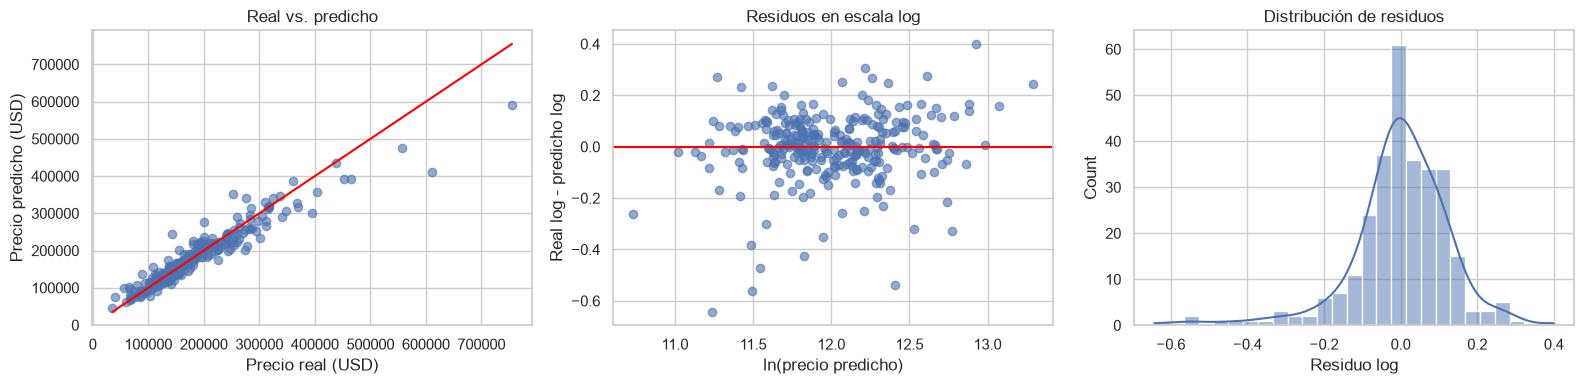

,Id,Real,Predicho,Error absoluto USD
898,899,611657,409892.470469,201764.529531
691,692,755000,591820.643349,163179.356651
588,589,143000,245001.214386,102001.214386
581,582,253293,351404.061019,98111.061019
774,775,395000,299587.449032,95412.550968
1046,1047,556581,474843.006940,81737.993060
529,530,200624,276409.540606,75785.540606
426,427,275000,202497.087899,72502.912101
1243,1244,465000,393111.179940,71888.820060
322,323,301000,234494.065473,66505.934527


In [9]:
y_val = validacion["SalePrice"]
pred_simple = simple.predict(validacion[["GrLivArea"]])
print("Precios no positivos del ejemplo simple:", int((pred_simple <= 0).sum()))
pred_simple = np.maximum(pred_simple, 1)
pred_log = elegido.predict(X_val)
pred_val = np.exp(pred_log)

def medir(real, predicho):
    return {
        "MAE USD": mean_absolute_error(real, predicho),
        "RMSE USD": np.sqrt(mean_squared_error(real, predicho)),
        "R2": r2_score(real, predicho),
        "RMSE log": np.sqrt(mean_squared_error(np.log(real), np.log(predicho)))
    }

metricas = pd.DataFrame({"Simple original": medir(y_val, pred_simple), nombre_elegido: medir(y_val, pred_val)}).T
display(metricas)
metricas.to_csv(SALIDA / "metricas_validacion.csv", index_label="Modelo")
resultados_cv.to_csv(SALIDA / "metricas_cv.csv")

residuos_log = np.log(y_val) - pred_log
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].scatter(y_val, pred_val, alpha=0.6)
limites = [min(y_val.min(), pred_val.min()), max(y_val.max(), pred_val.max())]
axes[0].plot(limites, limites, color="red")
axes[0].set(title="Real vs. predicho", xlabel="Precio real (USD)", ylabel="Precio predicho (USD)")
axes[1].scatter(pred_log, residuos_log, alpha=0.6)
axes[1].axhline(0, color="red")
axes[1].set(title="Residuos en escala log", xlabel="ln(precio predicho)", ylabel="Real log - predicho log")
sns.histplot(residuos_log, kde=True, ax=axes[2])
axes[2].set(title="Distribución de residuos", xlabel="Residuo log")
plt.tight_layout()
plt.show()
errores = pd.DataFrame({"Id": validacion["Id"], "Real": y_val, "Predicho": pred_val})
errores["Error absoluto USD"] = abs(errores["Real"] - errores["Predicho"])
display(errores.nlargest(10, "Error absoluto USD"))

## 10. Interpretar coeficientes y limitaciones
Mostramos coeficientes del modelo ajustado a desarrollo. Son asociaciones condicionadas a los demás predictores. Para una variable sin transformar, un aumento de una unidad se asocia aproximadamente con `100 × (exp(coeficiente) - 1)%` de cambio en precio. En superficies logarítmicas, la interpretación es de elasticidad aproximada; las categorías se comparan con su referencia. No podemos ordenar importancia directamente mezclando unidades.

Revisar residuos ayuda a detectar patrones y dispersión desigual, pero estos gráficos no demuestran por sí solos independencia ni normalidad. El logaritmo y varias características permiten una explicación más flexible, aunque el modelo conserva limitaciones con viviendas atípicas. Correlación no implica causalidad. Evitamos extrapolar sin cautela.

In [10]:
nombres_variables = elegido.named_steps["preparacion"].get_feature_names_out()
coeficientes = pd.Series(elegido.named_steps["regresion"].coef_, index=nombres_variables, name="Coeficiente en escala log")
print("Intercepto log:", elegido.named_steps["regresion"].intercept_)
display(coeficientes.to_frame())
if nombre_elegido == "Multiple log":
    coef_calidad = coeficientes["numero__OverallQual"]
    print(f"Una unidad de calidad se asocia a {(np.exp(coef_calidad)-1)*100:.2f}% de cambio, manteniendo los demás predictores.")

Intercepto log: 7.156144834331669


,Coeficiente en escala log
numero__OverallQual,0.046941
numero__OverallCond,0.052890
numero__LogGrLivArea,0.337741
numero__LogTotalBsmtSF,0.125325
numero__LogLotArea,0.089065
numero__GarageCars,0.058556
numero__Antiguedad,-0.002676
numero__DesdeRemodelacion,-0.000840
numero__FullBath,0.002620
numero__HalfBath,0.013262


Una unidad de calidad se asocia a 4.81% de cambio, manteniendo los demás predictores.


## 11. Reentrenar y generar archivos para Kaggle
Con la evaluación terminada, ajustamos el modelo seleccionado con las 1,460 viviendas. No cambiamos el algoritmo ni las variables. Conservamos el orden e IDs de `test.csv` y comprobamos estructura, filas y precios positivos.

También generamos `submission_simple.csv` con el ejemplo de clase, por si el profesor exige estrictamente una sola variable. **`submission.csv` usa el modelo seleccionado por validación cruzada**. El envío contiene precios en USD, nunca sus logaritmos.

In [11]:
elegido.fit(preparar_variables(train), np.log(train["SalePrice"]))
pred_test = np.exp(elegido.predict(preparar_variables(test)))
submission = pd.DataFrame({"Id": test["Id"], "SalePrice": pred_test})
assert submission.columns.tolist() == ejemplo.columns.tolist() == ["Id", "SalePrice"]
assert len(submission) == len(test) == len(ejemplo)
assert submission["Id"].tolist() == ejemplo["Id"].tolist()
assert np.isfinite(submission["SalePrice"]).all()
assert submission["SalePrice"].gt(0).all()
submission.to_csv(SALIDA / "submission.csv", index=False)

simple.fit(train[["GrLivArea"]], train["SalePrice"])
pred_simple_test = simple.predict(test[["GrLivArea"]])
print("Predicciones simples ajustadas al piso de 1 USD:", int((pred_simple_test <= 0).sum()))
submission_simple = pd.DataFrame({"Id": test["Id"], "SalePrice": np.maximum(pred_simple_test, 1)})
submission_simple.to_csv(SALIDA / "submission_simple.csv", index=False)
display(submission.head())
display(submission["SalePrice"].describe())
print("Archivo principal:", (SALIDA / "submission.csv").resolve())
print("Modelo del archivo principal:", nombre_elegido)

Predicciones simples ajustadas al piso de 1 USD: 0


C:\Users\dark_\miniconda3\envs\lab02_alca\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


,Id,SalePrice
0,1461,118482.138424
1,1462,156631.916813
2,1463,178254.120137
3,1464,193452.331103
4,1465,210323.296024


count      1459.000000
mean     177338.914108
std       73871.236061
min       38024.911891
25%      126385.668439
50%      160586.557314
75%      209311.430270
max      589304.369244
Name: SalePrice, dtype: float64

Archivo principal: C:\Users\dark_\Desktop\int-negocios\lab02_alca\lab07_alca\outputs\submission.csv
Modelo del archivo principal: Multiple log


## 12. Conclusiones y entrega
La tabla de métricas permite comprobar si incorporar varias características supera al ejemplo simple. El score local es una estimación y puede diferir del leaderboard por la distribución de viviendas. No prometemos una posición ni un puntaje público antes del envío.

El EDA identifica la asimetría de precios, asociaciones de calidad y superficie, datos faltantes y viviendas extremas. El modelo trata faltantes sin usar validación para calcular medianas; el barrio agrega información contextual. La evaluación informa MAE, RMSE, R² y RMSE log fuera de entrenamiento.

**Para entregar:**
1. En Kaggle abre la competencia y selecciona **Submit Predictions**.
2. Adjunta `outputs/submission.csv` (o la versión simple si esa es la exigencia del profesor).
3. Describe el envío como EDA + regresión lineal y espera su evaluación.
4. Registra abajo el score, fecha y posición que Kaggle muestre. El notebook se publica aparte, si el curso lo pide.

**Registro del envío:** pendiente. Score público: pendiente. Posición: pendiente.

Antes de exponer, explica por qué reservamos validación, qué significa la pendiente simple, por qué usamos logaritmos y por qué un R² alto en entrenamiento no garantiza buenas predicciones nuevas.